# Tema 15 · Reducir dimensiones: PCA, t-SNE y UMAP

Ver datos de muchas dimensiones en dos, y comprimir sin perder lo esencial.

Este cuaderno es el tema 15 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/15-reducir-dimensiones-pca-t-sne-y-umap/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q umap-learn==0.5.12

# Teoría

## La pregunta

Una foto de una cara de 64 × 64 píxeles son 4096 números. Un dígito escrito a mano y escaneado en una cuadrícula de 8 × 8 son 64 números. Para la computadora, cada dígito es un **punto en un espacio de 64 dimensiones**: uno por píxel. ¿Cómo se mira una nube de 1797 puntos en 64 dimensiones, si nuestros ojos solo ven dos o tres? ¿Y hace falta guardar los 4096 números de cada cara, o con muchos menos se puede reconstruir casi la misma foto?

Piensa en tu sombra. Eres un objeto de tres dimensiones y la sombra en la pared es plana, de dos. Aun así, según cómo pongas la linterna, la sombra te reconoce o no: de perfil se ven tu nariz y tu peinado; desde arriba solo una mancha redonda. **Reducir dimensiones** es buscar la mejor «linterna»: el ángulo desde el que la sombra de los datos conserva lo más importante.

En este tema vas a:

- entender la **proyección** de un punto sobre una recta y por qué la mejor recta es la de **máxima varianza**;
- programar **PCA** (análisis de componentes principales) desde cero con NumPy y compararlo con scikit-learn;
- elegir cuántas componentes usar con la **varianza explicada** y usar PCA para **comprimir** caras;
- dibujar dígitos de 64 dimensiones en un plano con **PCA**, **t-SNE** y **UMAP**, y saber qué **no** se puede concluir de esos mapas.

Necesitas el producto punto y la multiplicación de matrices del tema 3, y la varianza del tema 5. Del tema 14 (clustering) sirve la idea de aprendizaje **no supervisado**: aquí tampoco usamos etiquetas para nada, salvo para colorear los gráficos.

## Actividad: gira la sombra

Una nube de puntos en el plano y una recta que pasa por su centro. Cada punto proyecta su **sombra** sobre la recta: el punto de la recta que le queda más cerca. El segmento entre el punto y su sombra es lo que se pierde al quedarnos solo con la sombra. Gira la recta con el deslizador o arrastrando la bola coral.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/15-reducir-dimensiones-pca-t-sne-y-umap/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Gira la recta despacio y mira la barra «La varianza total, repartida»: la parte oscura es la **varianza de la sombra** (qué tan desparramadas quedan las sombras) y la clara es el **error de reconstrucción** (el promedio de los segmentos al cuadrado). ¿Cambia el largo total de la barra?
2. Busca a mano el ángulo con más varianza. ¿Coincide con el de menos error? Comprueba con «Ir a la mejor recta».
3. Cambia a la nube «casi redonda». ¿Qué tan distinta es la mejor recta de la peor?
4. Prueba la nube «dos grupos». ¿La mejor recta separa los grupos en la sombra?

Lo que acabas de encontrar es la **primera componente principal**: la recta donde la sombra conserva la mayor parte de la variación de los datos y, a la vez, donde menos se pierde. El resto del tema le pone fórmula y la lleva a 64 y 4096 dimensiones.

## Proyectar: la sombra de un punto

Empecemos en dos dimensiones, donde todo se puede dibujar. Los datos son **sintéticos**: las notas de Matemática y de Física de 200 estudiantes inventados, con la regla de que a quien le va bien en una tiende a irle bien en la otra. Lo primero es **centrar** la nube: restar a cada columna su media, para que el centro quede en el origen y las rectas que probemos pasen por él.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = 200
# Datos sintéticos: notas de Matemática y de Física de 200 estudiantes
mate = rng.normal(60, 12, size=n)
fisica = 60 + 0.8 * (mate - 60) + rng.normal(0, 6, size=n)
X = np.column_stack([mate, fisica])       # forma (200, 2)

# Centrar: restar la media de cada columna
Xc = X - X.mean(axis=0)
print("Forma:", X.shape)
print("Medias antes:", X.mean(axis=0).round(1))
print("Medias después:", Xc.mean(axis=0).round(1))

Forma: (200, 2)
Medias antes: [60.2 59.6]
Medias después: [0. 0.]


Una recta que pasa por el origen se describe con un **vector unitario** *u* (de largo 1) que apunta en su dirección; con un ángulo θ, *u* = (cos θ, sin θ). La sombra de un punto *x* sobre esa recta se calcula con el **producto punto** del tema 3:

$$t = \mathbf{x} \cdot \mathbf{u} \qquad \text{sombra} = t \; \mathbf{u}$$

El número *t* es la **coordenada** del punto sobre la recta: cuánto avanza en la dirección de *u*. Con un solo número por punto, en lugar de dos, ya redujimos de 2 dimensiones a 1. Para volver al plano multiplicamos *t* por *u*: eso es la **reconstrucción**, y lo que le falta para llegar al punto original es el error.

El punto, su sombra y el origen forman un triángulo rectángulo (la sombra es el punto de la recta más cercano, así que el segmento que se pierde es perpendicular a ella). Por **Pitágoras**:

$${\| \mathbf{x} \|}^{2} = {t}^{2} + {\| \mathbf{x} - t \mathbf{u} \|}^{2}$$

Promediando sobre todos los puntos, el lado izquierdo es la **varianza total** de la nube (fija: no depende de la recta). Como ‖*x*‖² = *x*₁² + *x*₂² y la nube está centrada, el promedio de *x*₁² es la varianza de la columna de Matemática y el de *x*₂², la de Física: la varianza total es la **suma de las varianzas de las dos columnas**. Del lado derecho, el primer término de la derecha es la **varianza de la sombra** (como la nube está centrada, las sombras tienen media cero) y el segundo es el **error de reconstrucción**. Lo que gana uno lo pierde el otro.

In [ ]:
def sombra(Xc, angulo):
    """Varianza de la sombra y error de reconstrucción sobre una recta."""
    rad = np.deg2rad(angulo)
    u = np.array([np.cos(rad), np.sin(rad)])  # dirección, de largo 1
    t = Xc @ u                    # la coordenada de cada sombra
    reconstruido = np.outer(t, u)  # la sombra, de vuelta en el plano
    varianza = np.mean(t ** 2)
    error = np.mean(np.sum((Xc - reconstruido) ** 2, axis=1))
    return varianza, error

total = np.mean(np.sum(Xc ** 2, axis=1))   # varianza total de la nube
print(f"Varianza total: {total:.1f}")
for angulo in [0, 45, 90]:
    v, e = sombra(Xc, angulo)
    print(f"{angulo:3d}°:  varianza {v:6.1f}  + error {e:6.1f}"
          f"  = {v + e:.1f}")

Varianza total: 248.7
  0°:  varianza  133.0  + error  115.6  = 248.7
 45°:  varianza  226.2  + error   22.5  = 248.7
 90°:  varianza  115.6  + error  133.0  = 248.7


La suma siempre da 248,7, la varianza total. Con la recta horizontal (0°) la sombra es solo la nota de Matemática y conserva 133 de los 248,7; con la vertical (90°), la de Física, 115,6. Fíjate que 133 + 115,6 da justamente la varianza total (248,6; sale 248,7 porque los números de arriba están redondeados). Con la diagonal (45°) la sombra conserva 226,2 y casi no se pierde nada. Busquemos el mejor ángulo probando los 180 (de 180° en adelante se repiten las mismas rectas):

Ángulo con más varianza: 43 grados
Ángulo con menos error:  43 grados


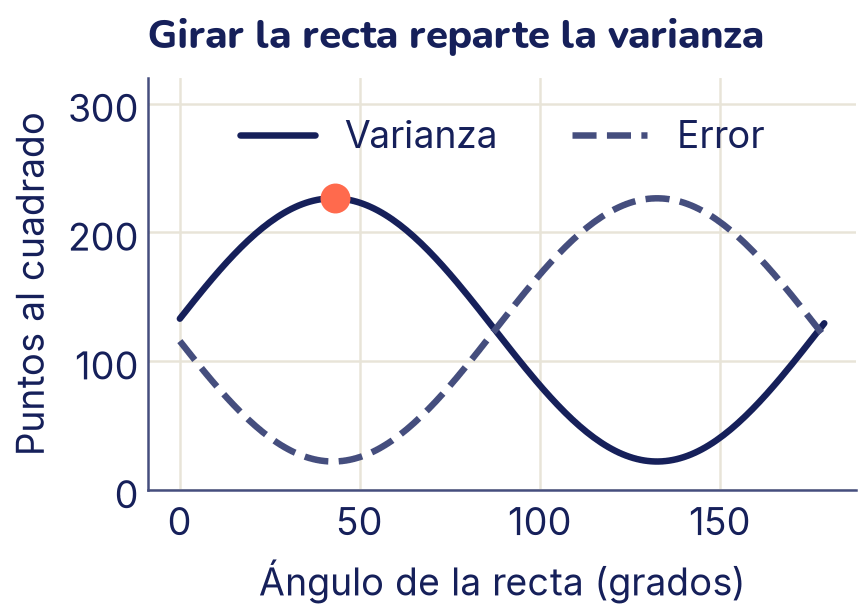

In [ ]:
angulos = np.arange(180)
resultados = np.array([sombra(Xc, a) for a in angulos])
varianzas, errores = resultados[:, 0], resultados[:, 1]
mejor = angulos[np.argmax(varianzas)]
print("Ángulo con más varianza:", mejor, "grados")
print("Ángulo con menos error: ", angulos[np.argmin(errores)], "grados")

plt.plot(angulos, varianzas, color="C0", label="Varianza")
plt.plot(angulos, errores, color="C2", linestyle="--",
         label="Error")
plt.scatter([mejor], [varianzas.max()], color="C1", s=120, zorder=3)
plt.ylim(0, 320)
plt.xlabel("Ángulo de la recta (grados)")
plt.ylabel("Puntos al cuadrado")
plt.title("Girar la recta reparte la varianza")
plt.legend(loc="upper center", ncol=2)
plt.show()

Las dos curvas son una el espejo de la otra: **el ángulo de máxima varianza es el mismo que el de mínimo error**. Es lo que viste en la actividad. Esa recta, a unos 43°, es la **primera componente principal**. Tiene sentido: quien saca buena nota en Matemática suele sacar buena nota en Física, así que la dirección «a los dos les va bien o a los dos les va mal» resume casi todo; podríamos llamarla «rendimiento en ciencias».

## Covarianza y vectores propios

Probar todos los ángulos funciona en 2 dimensiones, pero en 64 hay demasiadas direcciones para probarlas una por una. Hace falta un atajo, y lo da la **matriz de covarianza**. En el tema 5 la varianza medía cuánto se desparrama una columna. La **covarianza** de dos columnas es el promedio de los productos de sus valores centrados: es positiva si suelen subir juntas, negativa si cuando una sube la otra baja, y cercana a cero si no tienen que ver. Todas juntas forman una matriz; con los datos centrados en las filas de *X*, sale de una sola multiplicación de matrices:

$$C = \frac{1}{n} {X}^{T} X \qquad \text{varianza de la sombra} = {\mathbf{u}}^{T} C \mathbf{u}$$

Aquí hay tres ideas seguidas. Veámoslas una por una.

**1. Por qué *X*ᵀ*X*/*n* da las covarianzas.** Multiplicar matrices es «fila por columna»: se multiplica elemento por elemento y se suma (tema 3). *X*ᵀ es *X* transpuesta: sus filas son las columnas de *X*. Así, la fila 1 de *X*ᵀ es la columna de Matemática (los 200 valores centrados) y la columna 2 de *X* es la de Física. El elemento de la fila 1 y la columna 2 de *X*ᵀ*X* es entonces mate₁·física₁ + mate₂·física₂ + … + mate₂₀₀·física₂₀₀, y al dividir entre *n* queda el promedio de los productos: la covarianza de Matemática y Física. En la diagonal, una columna se multiplica por sí misma: el promedio de sus cuadrados, que con datos centrados es su varianza. Una sola multiplicación calcula todas las parejas a la vez.

**2. Por qué *u*ᵀ*Cu* es la varianza de la sombra.** La coordenada de la sombra es *t* = *u*₁*x*₁ + *u*₂*x*₂. Al cuadrado, *t*² = *u*₁²*x*₁² + 2*u*₁*u*₂*x*₁*x*₂ + *u*₂²*x*₂². Al promediar sobre todos los puntos, el promedio de *x*₁² es la varianza de Matemática (*C*₁₁), el de *x*₂² la de Física (*C*₂₂) y el de *x*₁*x*₂ su covarianza (*C*₁₂). Queda *u*₁²·*C*₁₁ + 2*u*₁*u*₂·*C*₁₂ + *u*₂²·*C*₂₂, que es justo lo que da la cuenta *u*ᵀ*Cu*. Por eso la varianza en **cualquier** dirección *u* se calcula con *C*, sin volver a tocar los datos.

**3. Por qué la mejor dirección es un vector propio.** Si multiplicas *C* por una dirección *u*, el resultado *Cu* casi nunca apunta hacia el mismo lado que *u*: *C* «empuja» cada dirección hacia donde la nube se estira más (abajo lo verás con números: la dirección de 0° sale empujada a 37°, y la de 90°, a 49°, las dos hacia los 43° de la mejor recta). Solo hay dos direcciones que *C* no gira, solo estira: la de la nube más estirada y su perpendicular. Esas direcciones se llaman **vectores propios** y el número por el que se estiran es su **valor propio** λ:

$$C \mathbf{u} = \lambda \mathbf{u}$$

Si un vector propio *u* (de largo 1) cumple *Cu* = λ*u*, la varianza de su sombra es *u*ᵀ*Cu* = λ·*u*ᵀ*u* = λ: **el valor propio es la varianza que conserva esa dirección**. Recuerda la actividad «Gira la sombra»: en la mejor recta, girar un poco hacia cualquier lado hace bajar la varianza; la nube queda equilibrada a los dos lados de la recta y *C* no la empuja hacia ninguno. El atajo es entonces este: la dirección de máxima varianza es el vector propio con el valor propio más grande. Que siempre es así se demuestra en los cursos de álgebra lineal de la universidad; aquí lo vamos a comprobar con los 180 ángulos que ya probamos.

No hace falta que sepas calcularlos a mano: NumPy lo hace con `np.linalg.eigh`, la versión para matrices simétricas como *C* (devuelve los valores propios de menor a mayor y los vectores en las columnas).

In [ ]:
# Matriz de covarianza: (2, 200) @ (200, 2) da (2, 2)
C = Xc.T @ Xc / n
print("Covarianza:\n", C.round(1))

valores, vectores = np.linalg.eigh(C)   # de menor a mayor
print("Valores propios:", valores.round(1))
print("Vectores propios (columnas):\n", vectores.round(3))

u1 = vectores[:, 1]             # el del valor propio más grande
# El ángulo de la flecha u1, llevado al rango de 0° a 180°
angulo_u1 = np.rad2deg(np.arctan2(u1[1], u1[0])) % 180
print(f"Ángulo de la primera componente: {angulo_u1:.1f}°")

Covarianza:
 [[133.  101.8]
 [101.8 115.6]]
Valores propios: [ 22.1 226.5]
Vectores propios (columnas):
 [[ 0.676 -0.737]
 [-0.737 -0.676]]
Ángulo de la primera componente: 42.6°


Comprobemos con números las tres ideas de arriba:

In [ ]:
# 1. Un elemento de C a mano: el promedio de los productos
print(f"Promedio de mate·física: {np.mean(Xc[:, 0] * Xc[:, 1]):.1f}")

# 2. u·C·u frente a la varianza de la sombra, con la recta de 45°.
# Con un vector a la izquierda, @ hace lo mismo que la transpuesta uᵀ
u45 = np.array([np.cos(np.deg2rad(45)), np.sin(np.deg2rad(45))])
print(f"u·C·u a 45°: {u45 @ C @ u45:.1f}"
      f"   sombra a 45°: {sombra(Xc, 45)[0]:.1f}")

# 3. C empuja las direcciones hacia la nube; al vector propio, no
for angulo in [0, 90]:
    u = np.array([np.cos(np.deg2rad(angulo)), np.sin(np.deg2rad(angulo))])
    Cu = C @ u
    girado = np.rad2deg(np.arctan2(Cu[1], Cu[0]))
    print(f"u a {angulo:2d}°:  C·u apunta a {girado:.1f}°")
print("C·u1: ", (C @ u1).round(1))
print("λ·u1: ", (valores[1] * u1).round(1))
print(f"Máximo de los 180 ángulos: {varianzas.max():.1f}"
      f"   valor propio: {valores[1]:.1f}")

Promedio de mate·física: 101.8
u·C·u a 45°: 226.2   sombra a 45°: 226.2
u a  0°:  C·u apunta a 37.4°
u a 90°:  C·u apunta a 48.6°
C·u1:  [-166.9 -153.2]
λ·u1:  [-166.9 -153.2]
Máximo de los 180 ángulos: 226.5   valor propio: 226.5


Las tres ideas se cumplen: el promedio de los productos es el 101,8 que está fuera de la diagonal de *C*; *u*ᵀ*Cu* da la misma varianza que proyectar los 200 puntos; *C* empuja las direcciones de 0° y 90° hacia la nube, pero a *u*₁ solo lo estira (*Cu*₁ = λ*u*₁); y el mejor de los 180 ángulos conserva la misma varianza que el valor propio más grande. Y lo que dice la salida de `eigh`:

- En la diagonal de *C* están las varianzas de cada columna: 133 (Matemática) y 115,6 (Física), las mismas que dieron las rectas de 0° y 90°. Fuera de la diagonal está la covarianza, 101,8: positiva y grande, porque las dos notas suben juntas.
- El valor propio grande, 226,5, es la varianza de la sombra sobre la mejor recta, y su vector propio apunta a 42,6°, el mismo ángulo que encontramos probando (allá, de grado en grado, salió 43). El vector sale con los dos signos negativos: apunta hacia abajo a la izquierda, pero es la misma recta. **El signo de un vector propio es arbitrario.**
- El otro valor propio, 22,1, es la varianza en la dirección perpendicular: la **segunda componente principal**. Los dos suman 248,6, la varianza total (salvo redondeo), igual que 133 + 115,6: girar los ejes reparte la varianza total de otra forma, pero no la cambia.

Dibujemos las dos componentes como flechas desde el centro, cada una de largo dos desviaciones estándar en su dirección:

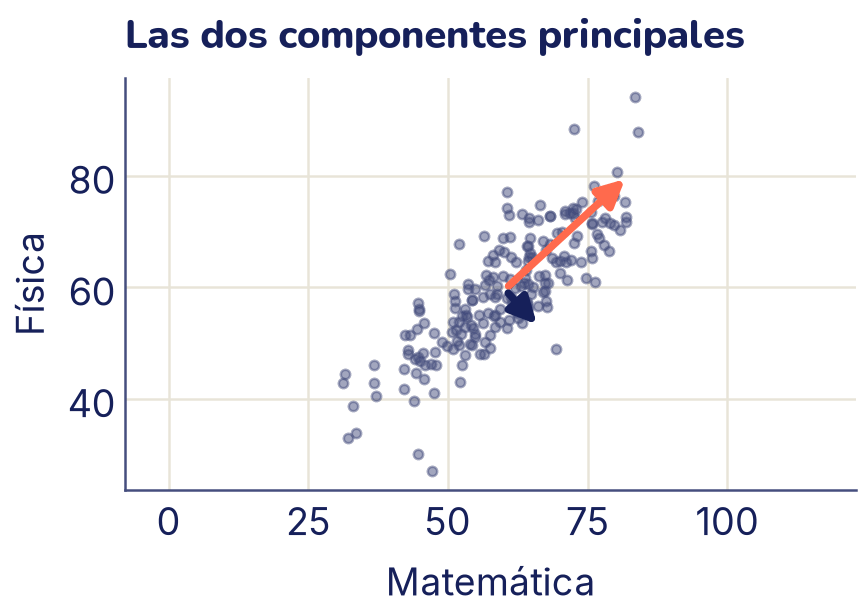

In [ ]:
centro = X.mean(axis=0)
plt.scatter(X[:, 0], X[:, 1], s=14, color="C2", alpha=0.5)
for k, color in [(1, "C1"), (0, "C0")]:
    # Flecha de largo 2 desviaciones estándar en cada dirección;
    # el signo de un vector propio es arbitrario: la giramos hacia +x
    flecha = 2 * np.sqrt(valores[k]) * vectores[:, k]
    flecha = flecha * np.sign(flecha[0])
    plt.annotate("", xy=centro + flecha, xytext=centro,
                 arrowprops=dict(arrowstyle="-|>", color=color, lw=3,
                                 mutation_scale=22))
plt.axis("equal")
plt.xlabel("Matemática")
plt.ylabel("Física")
plt.title("Las dos componentes principales")
plt.show()

La flecha larga es la primera componente: el eje a lo largo del cual la nube se estira más. La corta es la segunda, perpendicular a la primera. Las componentes principales son un **nuevo par de ejes** para los mismos datos, girados para alinearse con la forma de la nube. Si guardamos solo la coordenada sobre la flecha larga, perdemos 22,1 de 248,6, menos del 9 % de la varianza.

## PCA desde cero

**PCA** (del inglés *principal component analysis*) es exactamente esto, en tantas dimensiones como haga falta:

1. Centrar los datos.
2. Calcular la matriz de covarianza.
3. Sacar sus vectores propios y ordenarlos de mayor a menor valor propio: son las componentes principales.
4. Quedarse con las *k* primeras y proyectar los datos sobre ellas: cada punto pasa a tener *k* coordenadas.

La proporción de la varianza que conserva cada componente es su valor propio dividido entre la suma de todos: la **varianza explicada**. Probémoslo con los dígitos escritos a mano de scikit-learn (vienen incluidos, sin descarga): 1797 imágenes de 8 × 8 píxeles, cada una aplanada en una fila de 64 números entre 0 y 16.

In [ ]:
from sklearn.datasets import load_digits

digitos = load_digits()
Xd, yd = digitos.data, digitos.target
print("Forma de los dígitos:", Xd.shape)

def pca(X, k):
    """PCA desde cero: centrar, covarianza y vectores propios."""
    media = X.mean(axis=0)
    Xc = X - media
    C = Xc.T @ Xc / len(X)
    valores, vectores = np.linalg.eigh(C)
    orden = np.argsort(valores)[::-1]     # de mayor a menor
    valores, vectores = valores[orden], vectores[:, orden]
    componentes = vectores[:, :k].T        # forma (k, columnas)
    Z = Xc @ componentes.T                 # coordenadas nuevas
    return Z, componentes, valores / valores.sum()

Z, comps, proporcion = pca(Xd, 2)
print("Forma de Z:", Z.shape)
print("Proporción de varianza, 5 primeras:", proporcion[:5].round(3))

Forma de los dígitos: (1797, 64)
Forma de Z: (1797, 2)
Proporción de varianza, 5 primeras: [0.149 0.136 0.118 0.084 0.058]


La matriz de covarianza ahora es de 64 × 64, pero el código es el mismo de antes. Las primeras componentes conservan el 14,9 %, el 13,6 % y el 11,8 % de la varianza. Ninguna se lleva casi todo, como pasaba con las notas: los dígitos varían de muchas formas distintas. Comparemos con `PCA` de scikit-learn, que se usa como cualquier modelo: `fit` aprende las componentes y `transform` proyecta.

In [ ]:
from sklearn.decomposition import PCA

modelo = PCA(n_components=2).fit(Xd)
Z_sk = modelo.transform(Xd)
print("scikit-learn:", modelo.explained_variance_ratio_.round(3))
# Cada componente puede salir con el signo contrario: da igual
print("Mismas direcciones:",
      np.allclose(np.abs(modelo.components_), np.abs(comps)))
print("Mismas coordenadas:", np.allclose(np.abs(Z_sk), np.abs(Z)))

scikit-learn: [0.149 0.136]
Mismas direcciones: True
Mismas coordenadas: True


Lo mismo, salvo el signo de cada componente, que ya sabes que es arbitrario (por eso comparamos los valores absolutos). scikit-learn no usa `eigh` sino otra factorización, la **SVD**, más estable con muchos datos; en el ejercicio 2 compruebas que da lo mismo. Lo que aprende queda guardado en el modelo: `components_` (las direcciones), `mean_` (la media que restó) y `explained_variance_ratio_` (la proporción de varianza de cada componente).

## La varianza explicada

Con las 64 componentes no se pierde nada: es solo un cambio de ejes. La gracia está en quedarse con menos. Para elegir cuántas, se suma la varianza explicada de la primera, la segunda, y así: la **varianza explicada acumulada**.

Para 50% de la varianza:  5 componentes
Para 80% de la varianza: 13 componentes
Para 90% de la varianza: 21 componentes
Para 95% de la varianza: 29 componentes


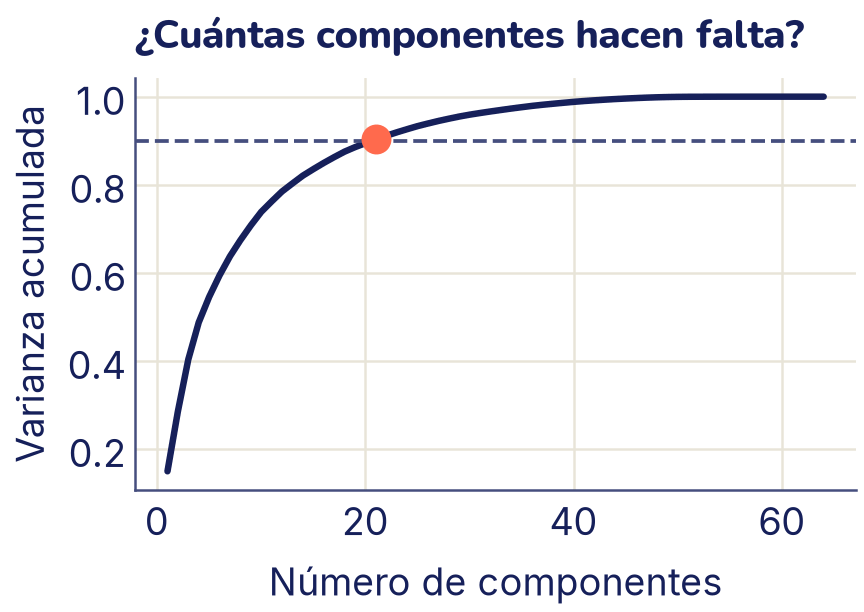

In [ ]:
completo = PCA().fit(Xd)                # las 64 componentes
acumulada = np.cumsum(completo.explained_variance_ratio_)
for meta in [0.5, 0.8, 0.9, 0.95]:
    k = np.argmax(acumulada >= meta) + 1  # primera que llega a la meta
    print(f"Para {meta:.0%} de la varianza: {k:2d} componentes")

k90 = np.argmax(acumulada >= 0.9) + 1
plt.plot(np.arange(1, 65), acumulada, color="C0")
plt.axhline(0.9, color="C2", linestyle="--", linewidth=1.5)
plt.scatter([k90], [acumulada[k90 - 1]], color="C1", s=120, zorder=3)
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.title("¿Cuántas componentes hacen falta?")
plt.show()

Con 21 de los 64 números de cada dígito se conserva el 90 % de la varianza, y con 29, el 95 %. Las últimas componentes casi no aportan: corresponden sobre todo a detalles chicos y a los píxeles del borde, que casi siempre están vacíos (sin tinta). Una regla habitual es elegir *k* para llegar al 90 % o al 95 %. Pero lo que más importa es para qué lo vas a usar: si PCA es un paso previo a un clasificador, lo mejor es elegir *k* según la exactitud del clasificador con datos de validación (ejercicio 4), con PCA dentro del pipeline, como el escalador del tema 10.

## Los dígitos en un plano

Para **mirar** los datos nos quedamos con 2 componentes, aunque solo conserven el 28,5 % de la varianza (14,9 % + 13,6 %). PCA es **lineal**: la sombra se proyecta siempre sobre un plano recto. Si los grupos de los datos están enredados de una forma que ningún plano recto separa, PCA los va a mostrar superpuestos. Para eso hay dos métodos **no lineales** muy usados.

**t-SNE** (se lee «ti-esne») no busca una buena sombra, sino conservar **vecindarios**. Primero, para cada punto, mira qué otros puntos tiene cerca en las 64 dimensiones y a cada uno le da una probabilidad de ser «su vecino». Después coloca todos los puntos en un plano, al principio casi al azar, y los va moviendo poco a poco (con descenso de gradiente, como en el tema 6) hasta que los vecinos del plano se parezcan a los de las 64 dimensiones. Su parámetro principal es la **perplejidad**: más o menos, cuántos vecinos mira cada punto (lo típico es entre 5 y 50; por defecto, 30).

**UMAP** tiene la misma idea, con otra matemática: arma un grafo que une cada punto con sus vecinos más cercanos (como el grafo de vecinos del clustering espectral del tema 14) y busca un dibujo en el plano que respete ese grafo. Sus dos perillas son `n_neighbors`, cuántos vecinos mira (como la perplejidad), y `min_dist`, qué tan apretados se permiten los puntos en el dibujo. Suele ser más rápido que t-SNE con muchos datos y, a diferencia de t-SNE, puede ubicar puntos nuevos con `transform`.

UMAP no viene con scikit-learn: es la librería `umap-learn`. En Colab, si `import umap` da `ModuleNotFoundError`, ejecuta antes en una celda aparte `!pip install umap-learn` (el signo de exclamación le dice a Colab que es un comando para instalar, no Python). Se instala como `umap-learn`, pero se importa como `umap`.

Los dos métodos parten de algo **al azar**, así que fijamos `random_state` para que el resultado se repita. En UMAP también pasamos `n_jobs=1`: con varios hilos de cálculo el resultado podría cambiar un poco de una corrida a otra. Este bloque tarda unos segundos; la primera vez, UMAP tarda un poco más porque prepara su código.

¿Cómo medir si un mapa de 2 dimensiones conserva lo importante? Una forma simple: para cada dígito, buscar su vecino más cercano en el mapa y ver si es el mismo dígito. Las etiquetas no se usaron para hacer el mapa, solo para revisarlo.

In [ ]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
import umap

tsne = TSNE(n_components=2, perplexity=30, random_state=0)
Z_tsne = tsne.fit_transform(Xd)
reductor = umap.UMAP(n_neighbors=15, min_dist=0.1,
                     random_state=0, n_jobs=1)
Z_umap = reductor.fit_transform(Xd)

def vecino_igual(E, y):
    """Fracción de puntos cuyo vecino más cercano es el mismo dígito."""
    vecinos = NearestNeighbors(n_neighbors=2).fit(E)
    indices = vecinos.kneighbors(E, return_distance=False)[:, 1]
    return np.mean(y[indices] == y)

for nombre, E in [("64 dimensiones", Xd), ("PCA 2D", Z_sk),
                  ("t-SNE 2D", Z_tsne), ("UMAP 2D", Z_umap)]:
    print(f"{nombre:15s} {vecino_igual(E, yd):.1%}")

64 dimensiones  98.8%
PCA 2D          58.7%
t-SNE 2D        98.8%
UMAP 2D         98.0%


En las 64 dimensiones originales, el vecino más cercano de un dígito es del mismo dígito el 98,8 % de las veces. El plano de PCA baja eso a 58,7 %: la sombra superpone a muchos dígitos distintos. t-SNE conserva el 98,8 % y UMAP el 98,0 %: casi todos los vecindarios sobrevivieron al viaje de 64 a 2 dimensiones. Mirémoslo. En cada mapa, los dígitos son puntos grises con su número encima del centro de su grupo, y los unos van en coral:

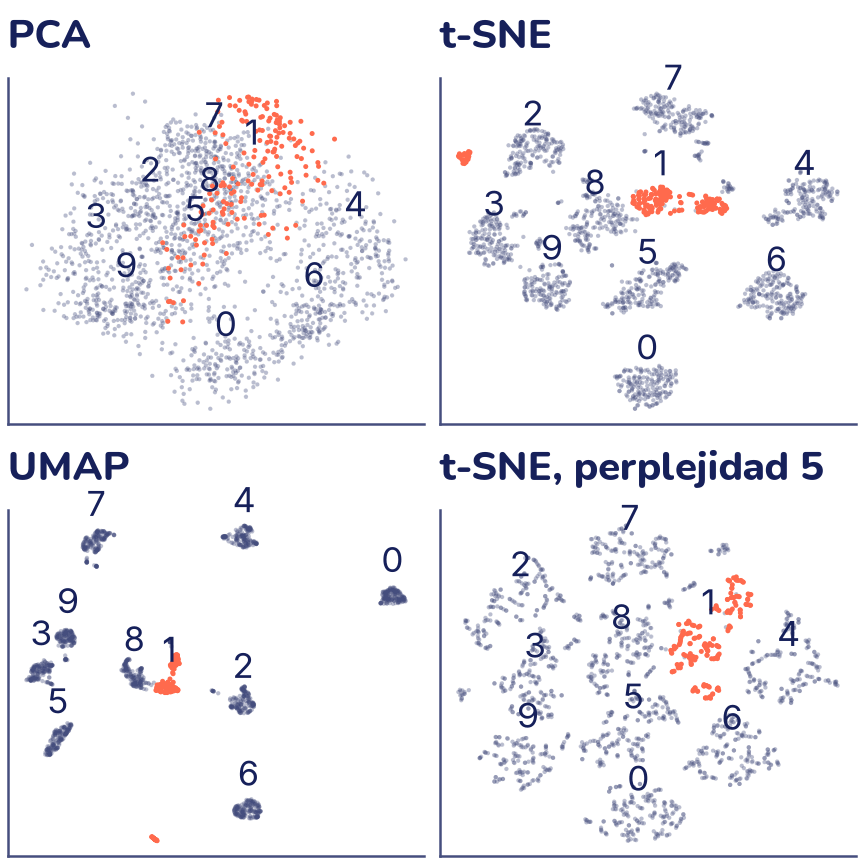

In [ ]:
def dibujar_mapa(eje, E, titulo, destacado=1):
    """Los puntos en gris, uno de los dígitos en coral y las etiquetas."""
    es = yd == destacado
    eje.scatter(E[~es, 0], E[~es, 1], s=3, color="C2", alpha=0.35,
                edgecolors="none")
    eje.scatter(E[es, 0], E[es, 1], s=4, color="C1", edgecolors="none")
    for d in range(10):
        # La etiqueta va un poco arriba del centro de cada dígito
        centro = np.median(E[yd == d], axis=0)
        eje.annotate(str(d), centro, xytext=(0, 10),
                     textcoords="offset points", ha="center",
                     fontsize=14, fontweight="semibold", color="C0")
    eje.set_title(titulo)
    eje.set_xticks([])
    eje.set_yticks([])

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
dibujar_mapa(ejes[0, 0], Z_sk, "PCA")
dibujar_mapa(ejes[0, 1], Z_tsne, "t-SNE")
dibujar_mapa(ejes[1, 0], Z_umap, "UMAP")
# t-SNE otra vez, ahora mirando solo 5 vecinos
Z_tsne5 = TSNE(n_components=2, perplexity=5,
               random_state=0).fit_transform(Xd)
dibujar_mapa(ejes[1, 1], Z_tsne5, "t-SNE, perplejidad 5")
plt.show()

- **PCA** muestra una sola nube: el 0, el 4 y el 6 se asoman en los bordes, pero en el centro el 1, el 7, el 8 y el 5 se superponen. Sus ejes sí significan algo: son las dos direcciones de más varianza de los píxeles.
- **t-SNE** separa los diez dígitos en grupos. Los unos coral forman un grupo alargado y además un grupito aparte, junto al 2: hay más de una forma de escribir un 1 (con o sin la rayita de abajo, por ejemplo), y t-SNE lo descubrió sin saber qué es un 1.
- **UMAP** también separa los diez dígitos, con grupos más apretados (eso lo controla `min_dist`) y también con un grupito suelto de unos.
- **t-SNE con perplejidad 5** mira tan pocos vecinos que los grupos se desarman en hilos y pedazos. No es un mapa «equivocado»: es otra vista, más local, de los mismos datos.

## Lo que un mapa no dice

Estos mapas son muy útiles para **explorar**, pero es fácil leerles más de lo que dicen. Lo que conservan son los **vecindarios**: qué puntos estaban cerca de cuáles. Casi todo lo demás puede deformarse:

- **El tamaño de un grupo no dice cuán variado es.** t-SNE tiende a darles a todos los grupos un tamaño parecido.
- **La distancia entre dos grupos dice poco.** En el mapa de t-SNE el grupo más cercano al 0 es el 5, pero en los píxeles el dígito promedio más parecido al 0 es el 9 (lo compruebas en el ejercicio 5).
- **Los ejes no tienen nombre.** Girar o reflejar un mapa de t-SNE da un mapa igual de bueno.
- **Cada corrida y cada parámetro dan un mapa algo distinto.** Confía solo en lo que se repite al cambiar la semilla, la perplejidad o `n_neighbors`.

Comprobemos la primera con datos sintéticos que conocemos: dos grupos en 10 dimensiones, uno apretado y otro diez veces más ancho.

In [ ]:
rng = np.random.default_rng(1)
# Datos sintéticos en 10 dimensiones: un grupo apretado y uno disperso
apretado = rng.normal(0, 1, size=(200, 10))
disperso = rng.normal(0, 10, size=(200, 10)) + 100
A = np.vstack([apretado, disperso])
E = TSNE(n_components=2, random_state=0).fit_transform(A)

def ancho(P):
    """Distancia promedio de los puntos a su centro."""
    return np.mean(np.linalg.norm(P - P.mean(axis=0), axis=1))

print(f"En 10 dimensiones: el disperso es "
      f"{ancho(A[200:]) / ancho(A[:200]):.1f} veces más ancho")
print(f"En el mapa t-SNE:  el disperso es "
      f"{ancho(E[200:]) / ancho(E[:200]):.1f} veces más ancho")

En 10 dimensiones: el disperso es 10.0 veces más ancho
En el mapa t-SNE:  el disperso es 1.0 veces más ancho


En los datos, un grupo es diez veces más ancho que el otro; en el mapa de t-SNE, los dos tienen el mismo ancho. t-SNE se adapta a la densidad de cada zona: dentro de cada grupo reparte los puntos para que los vecinos se vean, y en eso se pierde la escala. Si hubieras visto solo el mapa, habrías concluido que los dos grupos eran igual de variados.

Por eso t-SNE y UMAP se usan para **mirar** y generar preguntas, y PCA para **comprimir** y como paso previo de otros modelos: sus componentes son direcciones fijas que se pueden aplicar a cualquier dato nuevo y sus distancias se parecen a las originales si conservas suficientes componentes.

## Comprimir caras: las eigencaras

Ahora usemos PCA para lo segundo: guardar menos números. El dataset de caras de Olivetti tiene 400 fotos en escala de grises de 64 × 64 píxeles: 40 personas, 10 fotos de cada una. Viene con scikit-learn, pero hay que **descargarlo la primera vez** (unos 4 MB, desde el servidor de scikit-learn); después queda guardado en la computadora (en Colab, hasta que se reinicie el entorno).

Para ser honestos con la prueba, apartamos una foto de cada persona: el PCA aprende con 360 fotos y al final probamos con una que no vio. Las componentes son vectores de 4096 números, así que también se pueden mirar como imágenes: se llaman **eigencaras** (*eigen* es «propio» en alemán, como en vector propio). Para dibujarlas usamos un mapa de color que va de la tinta al blanco; en Colab puedes usar `cmap="gray"`.

Forma: (400, 4096)
Para ajustar: (360, 4096)   para probar: (40, 4096)
  5 componentes: 54.1% de la varianza
 20 componentes: 76.5% de la varianza
100 componentes: 93.9% de la varianza
200 componentes: 98.2% de la varianza


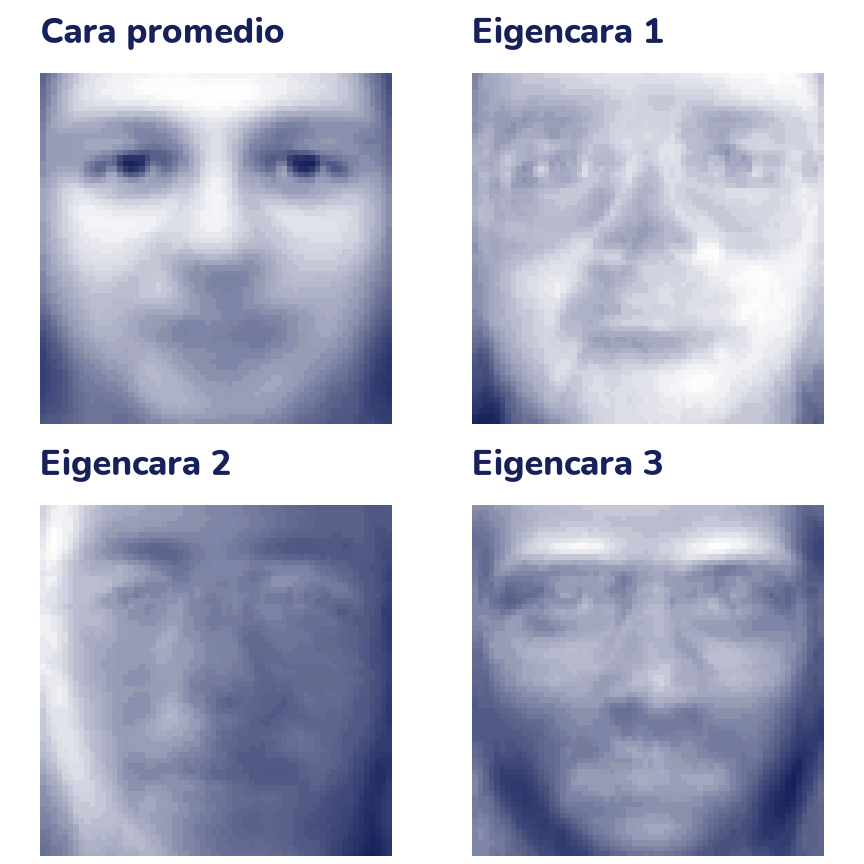

In [ ]:
from sklearn.datasets import fetch_olivetti_faces
from matplotlib.colors import LinearSegmentedColormap

caras = fetch_olivetti_faces()       # se descarga la primera vez
Xf = caras.data                      # 400 caras de 64 × 64 = 4096
print("Forma:", Xf.shape)

# Guardamos una foto de cada persona para probar al final
prueba = np.arange(len(Xf)) % 10 == 9
Xf_entr, Xf_prueba = Xf[~prueba], Xf[prueba]
print("Para ajustar:", Xf_entr.shape, "  para probar:", Xf_prueba.shape)

pca_caras = PCA(n_components=200, random_state=0).fit(Xf_entr)
acum = np.cumsum(pca_caras.explained_variance_ratio_)
for k in [5, 20, 100, 200]:
    print(f"{k:3d} componentes: {acum[k - 1]:.1%} de la varianza")

# Un mapa de color de la tinta al blanco (en Colab: "gray")
gris = LinearSegmentedColormap.from_list("gris", ["C0", "white"])
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
imagenes = [pca_caras.mean_] + list(pca_caras.components_[:3])
titulos = ["Cara promedio", "Eigencara 1", "Eigencara 2", "Eigencara 3"]
for eje, img, titulo in zip(ejes.flat, imagenes, titulos):
    eje.imshow(img.reshape(64, 64), cmap=gris)
    eje.set_title(titulo, fontsize=14)
    eje.axis("off")
plt.show()

La **cara promedio** es el centro de la nube: la cara que PCA resta antes de todo. Cada **eigencara** es una dirección en la que las caras varían mucho: a ojo, la primera tiene que ver sobre todo con la iluminación y la forma general, la segunda con la luz que llega más de un lado que del otro, y la tercera con las cejas, los ojos y el contorno. PCA no sabe nada de caras: estas direcciones salen solo de cómo varían los píxeles. Toda cara se aproxima como la cara promedio más una mezcla de eigencaras:

$$\text{cara} \approx \text{promedio} + {z}_{1} \cdot {\text{eigencara}}_{1} + {z}_{2} \cdot {\text{eigencara}}_{2} + \cdots + {z}_{k} \cdot {\text{eigencara}}_{k}$$

Los *k* números *z* (las coordenadas, con el mismo producto punto de la sombra) son **todo lo que hay que guardar de cada cara**: la cara promedio y las eigencaras se guardan una sola vez para todas. Con 5 componentes se conserva el 54,1 % de la varianza; con 20, el 76,5 %, y con 100, el 93,9 %. Reconstruyamos la foto que el PCA no vio:

  5 números: error cuadrático medio 0.0141
 20 números: error cuadrático medio 0.0078
100 números: error cuadrático medio 0.0044


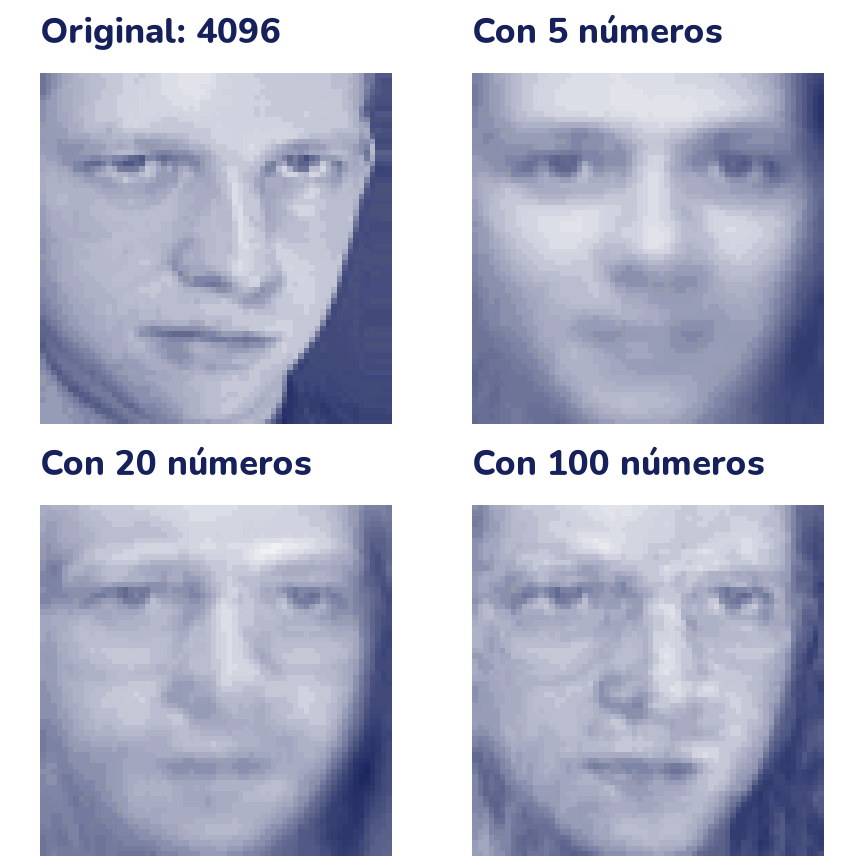

In [ ]:
cara = Xf_prueba[[0]]            # una foto que el PCA no vio, forma (1, 4096)
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
ejes[0, 0].imshow(cara.reshape(64, 64), cmap=gris, vmin=0, vmax=1)
ejes[0, 0].set_title("Original: 4096", fontsize=14)
for eje, k in zip([ejes[0, 1], ejes[1, 0], ejes[1, 1]], [5, 20, 100]):
    W = pca_caras.components_[:k]       # las k primeras, forma (k, 4096)
    z = (cara - pca_caras.mean_) @ W.T  # k números por cara
    reconstruida = pca_caras.mean_ + z @ W
    error = np.mean((cara - reconstruida) ** 2)
    print(f"{k:3d} números: error cuadrático medio {error:.4f}")
    eje.imshow(reconstruida.reshape(64, 64), cmap=gris, vmin=0, vmax=1)
    eje.set_title(f"Con {k} números", fontsize=14)
for eje in ejes.flat:
    eje.axis("off")
plt.show()

Con 5 números sale una cara cualquiera, casi la promedio. Con 20 ya aparecen los ojos, las cejas y la boca de esta persona, aunque borrosos. Con 100, unas 40 veces menos números que los 4096 píxeles, la persona se reconoce, aunque con ruido. El error cuadrático medio por píxel baja de 0,0141 a 0,0078 y a 0,0044. Y esto con una foto que el PCA nunca vio: aprendió de las otras 360 cómo varían las caras en general.

## Lo que aprendiste y lo que sigue

- **Proyectar** es quedarse con la sombra de los datos sobre una recta o un plano: la coordenada es un producto punto. Por Pitágoras, la varianza de la sombra más el error de reconstrucción es siempre la varianza total, así que **máxima varianza y mínimo error son la misma recta**.
- Las **componentes principales** son los vectores propios de la matriz de covarianza, ordenados por su valor propio, que es la varianza que conserva cada una. PCA desde cero son unas diez líneas de NumPy; `PCA` de scikit-learn da lo mismo, salvo el signo.
- La **varianza explicada acumulada** ayuda a elegir cuántas componentes guardar. PCA sirve para **comprimir** (las eigencaras) y como **preprocesamiento**, dentro del pipeline.
- **t-SNE** y **UMAP** dibujan datos de muchas dimensiones en un plano conservando los **vecindarios**. Sirven para mirar, pero los tamaños de los grupos, las distancias entre grupos y los ejes no se interpretan, y cada corrida puede cambiar.

Las redes neuronales de la fase 4 también aprenden representaciones de pocas dimensiones, pero no lineales; en el tema 22 vas a ver *embeddings* de palabras y vas a usar estos mismos mapas para mirarlos, y en el tema 29 un **autoencoder**, que es como un PCA hecho con una red.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que se definió en la teoría: `sombra`, `pca`, `vecino_igual`, los dígitos (`Xd`, `yd`) y el mapa t-SNE `Z_tsne`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. La sombra a mano

Tres puntos ya centrados: (2, 1), (−1, 0) y (−1, −1).

a) Proyéctalos sobre el eje horizontal, la recta de 0°. ¿Cuánto vale la varianza de la sombra? ¿Y el error de reconstrucción? Repite para la recta de 90°.

b) Calcula a mano la matriz de covarianza (recuerda: es `Xc.T @ Xc / n`).

c) Sin calcular nada más: ¿cuánto suman los dos valores propios? Compruébalo con `np.linalg.eigh` y busca el ángulo de la primera componente.

<details>
<summary>Respuesta</summary>

a) Sobre la recta de 0°, la sombra de cada punto es su coordenada *x*: 2, −1 y −1. La varianza de la sombra es (4 + 1 + 1) / 3 = **2**. Lo que se pierde es la coordenada *y* (1, 0 y −1), así que el error es (1 + 0 + 1) / 3 = **2/3 ≈ 0,67**. Sobre la recta de 90° se intercambian: varianza 2/3 y error 2. En los dos casos la suma es 8/3 ≈ 2,67, la varianza total.

b) Los elementos de la diagonal son las varianzas de cada columna, 2 y 2/3. Fuera de la diagonal va el promedio de los productos *x*·*y*: (2·1 + (−1)·0 + (−1)·(−1)) / 3 = 3/3 = **1**.

c) Suman lo mismo que la diagonal, 8/3: la varianza total no cambia al girar los ejes, solo se reparte distinto.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
P = np.array([[2, 1], [-1, 0], [-1, -1]])
print("0°:  varianza y error", np.round(sombra(P, 0), 2))
print("90°: varianza y error", np.round(sombra(P, 90), 2))
C3 = P.T @ P / 3
valores3, vectores3 = np.linalg.eigh(C3)
print("Valores propios:", valores3.round(3),
      " suma:", valores3.sum().round(3))
v = vectores3[:, 1]
print(f"Ángulo de la primera componente: "
      f"{np.rad2deg(np.arctan2(v[1], v[0])) % 180:.1f}°")

<details>
<summary>Respuesta (sigue)</summary>

La primera componente se lleva casi toda la varianza: es una recta inclinada unos 28°, entre el eje horizontal (que ya era bueno) y la diagonal.

</details>

### 2. PCA con SVD (desafío)

Hay otra forma de calcular las componentes sin armar la matriz de covarianza: la **descomposición en valores singulares** (SVD), que NumPy trae como `np.linalg.svd`. La intuición: SVD escribe los datos como un producto de tres matrices, «giro × estiramiento × giro». `Vt` da las direcciones de los ejes, `S` (los **valores singulares**) cuánto se estira la nube en cada uno y `U` dónde queda cada punto. Por qué funciona se ve en álgebra lineal; aquí solo vas a comprobar que da lo mismo. Escribe `Xc = U · S · Vt`; las filas de `Vt` son las componentes principales y cada valor singular al cuadrado, dividido entre *n*, es la varianza de su componente. Comprueba con los dígitos que da lo mismo que tu función `pca`.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
Xd_c = Xd - Xd.mean(axis=0)
U, S, Vt = np.linalg.svd(Xd_c, full_matrices=False)
varianzas_svd = S ** 2 / len(Xd)
print("Proporción con SVD:  ",
      (varianzas_svd / varianzas_svd.sum())[:5].round(3))

Z2, comps2, proporcion2 = pca(Xd, 2)
print("Proporción con eigh: ", proporcion2[:5].round(3))
print("Mismas componentes:", np.allclose(np.abs(Vt[:2]), np.abs(comps2)))

<details>
<summary>Respuesta</summary>

Dan lo mismo, salvo el signo de cada componente, que es arbitrario. scikit-learn usa SVD por dentro porque es más estable numéricamente y no necesita formar la matriz de covarianza, que con muchas columnas es enorme.

</details>

### 3. ¿Escalar antes de PCA?

El dataset `load_wine` de scikit-learn tiene 13 mediciones químicas de 178 vinos. Haz PCA con las columnas tal como vienen y mira qué proporción de la varianza se lleva la primera componente y qué columna pesa más en ella. Después estandariza las columnas (tema 10) y repite. ¿Qué pasó?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

vinos = load_wine()
nombres = np.array(vinos.feature_names)
desviaciones = vinos.data.std(axis=0)
for j in [0, 4, 12]:
    print(f"Desviación de {nombres[j]}: {desviaciones[j]:.1f}")

for titulo, datos in [("Sin escalar", vinos.data),
                      ("Estandarizado",
                       StandardScaler().fit_transform(vinos.data))]:
    p = PCA().fit(datos)
    principal = nombres[np.argmax(np.abs(p.components_[0]))]
    print(f"{titulo}: la 1.ª componente explica "
          f"{p.explained_variance_ratio_[0]:.1%}; pesa más {principal}")

<details>
<summary>Respuesta</summary>

Sin escalar, la columna `proline` tiene una desviación de unos 300, mientras la mayoría de las demás andan entre 0,1 y 15. La varianza es desviación al cuadrado, así que `proline` se lleva casi toda la varianza y la «primera componente» es básicamente esa columna sola: PCA no descubrió nada, solo midió unidades. Estandarizado, cada columna aporta lo mismo, la primera componente explica alrededor de un tercio y mezcla varias mediciones químicas. Regla: **si las columnas están en unidades distintas, estandariza antes de PCA** (en los dígitos no hizo falta porque todos los píxeles van de 0 a 16).

</details>

### 4. PCA antes de k-NN

Usa PCA como **preprocesamiento** de un clasificador k-NN (tema 8) para los dígitos. Separa un 25 % para validar (`train_test_split` con `random_state=0` y `stratify=yd`), arma un `make_pipeline(PCA(m), KNeighborsClassifier(5))` y mide la exactitud para un número de componentes *m* = 1, 2, 3, 5, 10, 20, 40 y 64 (lo llamamos *m* para no confundirlo con los *k* = 5 vecinos del k-NN). ¿Con cuántas componentes ya no vale la pena seguir subiendo?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

X_entr, X_val, y_entr, y_val = train_test_split(
    Xd, yd, test_size=0.25, random_state=0, stratify=yd)

for m in [1, 2, 3, 5, 10, 20, 40, 64]:
    tubo = make_pipeline(PCA(n_components=m, random_state=0),
                         KNeighborsClassifier(n_neighbors=5))
    tubo.fit(X_entr, y_entr)
    print(f"{m:2d} componentes: exactitud {tubo.score(X_val, y_val):.3f}")

<details>
<summary>Respuesta</summary>

Con 1 o 2 componentes el k-NN se confunde mucho (es lo que viste en el panel de PCA: los dígitos superpuestos). Con 10 ya pasa del 96 % y desde unas 20 se queda prácticamente igual que con los 64 píxeles. Es decir: con un tercio de los números se clasifica igual de bien, y el k-NN, que compara distancias con todos los ejemplos, trabaja tres veces menos. El PCA va **dentro del pipeline** para que se ajuste solo con los datos de entrenamiento (tema 10): ajustarlo con todos sería una pequeña fuga de datos.

</details>

### 5. Leer un mapa de t-SNE

Mira el panel «t-SNE» de la figura de los dígitos en la teoría. Tres de estas afirmaciones son conclusiones que **no** se pueden sacar del mapa y una sí. ¿Cuál es cuál y por qué?

1. El grupo del 0 queda más cerca del 5 que de cualquier otro dígito, así que los ceros se parecen más a los cincos que a los demás dígitos.
2. Los puntos de un mismo grupito del mapa suelen ser vecinos también en las 64 dimensiones.
3. El eje horizontal mide alguna propiedad de los dígitos, como el grosor del trazo.
4. Con perplejidad 5 los grupos se ven más sueltos y a otras distancias, así que uno de los dos mapas está mal.

<details>
<summary>Respuesta</summary>

La **2** es la que sí vale: t-SNE se esfuerza justamente en que los vecinos cercanos sigan cerca. Lo comprobaste en la teoría: el vecino más cercano en el mapa es del mismo dígito en el 98,8 % de los casos.

Las otras tres son falsas:

1. **Las distancias entre grupos no significan mucho.** t-SNE cuida los vecindarios, no la distancia entre grupos lejanos. Mídelo en las 64 dimensiones, con el dígito promedio de cada grupo:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
centros = np.array([Xd[yd == d].mean(axis=0) for d in range(10)])
dist_64 = np.linalg.norm(centros - centros[0], axis=1)
centros_mapa = np.array([np.median(Z_tsne[yd == d], axis=0)
                         for d in range(10)])
dist_mapa = np.linalg.norm(centros_mapa - centros_mapa[0], axis=1)
print("Del 0 al más cercano, en 64 dimensiones:", np.argsort(dist_64)[1:4])
print("Del 0 al más cercano, en el mapa t-SNE: ",
      np.argsort(dist_mapa)[1:4])

<details>
<summary>Respuesta (sigue)</summary>

   En los píxeles, el dígito más parecido al 0 promedio es el 9, no el 5.

3. **Los ejes no tienen nombre.** Si giras o reflejas el mapa entero, es igual de bueno: t-SNE solo mira qué puntos quedan cerca de cuáles. En PCA, en cambio, cada eje sí es una dirección concreta de los datos originales.

4. **Los dos mapas son vistas válidas.** La perplejidad dice cuántos vecinos mira cada punto: con 5, cada punto solo se preocupa por sus vecinos más inmediatos y los grupos se desarman en hilos y grumitos. Por eso se prueban varios valores y solo se confía en lo que se repite (como que el 1 se parte en dos grupos y que unos cuantos unos quedan cerca del 2 o sueltos).

</details>

## Mini-proyecto: un compresor de imágenes con PCA

Vas a comprimir una foto en escala de grises con PCA y dibujar la curva calidad–tamaño.

1. Carga la foto `china.jpg` que trae scikit-learn (`from sklearn.datasets import load_sample_image`), pásala a gris con un promedio de los tres canales y divide entre 255. Te queda una matriz de 427 × 640.
2. Trata **cada fila** de la imagen como un ejemplo de 640 números. Ajusta `PCA(n_components=k)` con las 427 filas y reconstruye la imagen con `inverse_transform(transform(...))`.
3. Cuenta cuántos números hay que guardar: *k* coordenadas por fila, *k* componentes de 640 números y la fila promedio. Divídelo entre los 427 · 640 números de la imagen original: es el **tamaño** relativo.
4. Mide la **calidad** con el error cuadrático medio entre la imagen original y la reconstruida.
5. Repite para *k* = 5, 10, 20, 50 y 100. Dibuja el error frente al tamaño y muestra las imágenes reconstruidas con el mapa de color `gris` de la teoría.
6. Escribe tres conclusiones: ¿desde qué *k* ya no notas la diferencia a simple vista? ¿Qué partes de la foto se arreglan primero y cuáles al final? ¿Le ganarías a un JPG?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 4 sin gráficos; tus números deberían coincidir.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.datasets import load_sample_image

foto = load_sample_image("china.jpg").mean(axis=2) / 255
alto, ancho = foto.shape
print("Forma:", foto.shape)

for k in [5, 10, 20, 50, 100]:
    p = PCA(n_components=k, random_state=0).fit(foto)
    reconstruida = p.inverse_transform(p.transform(foto))
    guardados = k * alto + k * ancho + ancho
    error = np.mean((foto - reconstruida) ** 2)
    print(f"k = {k:3d}:  tamaño {guardados / foto.size:5.1%}"
          f"   error {error:.4f}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

- La curva baja rápido al principio y después se aplana: las primeras componentes se llevan lo grueso (las zonas grandes de luz y sombra) y las siguientes van agregando detalles cada vez más finos, como bordes y texturas.
- Con *k* = 50, guardando una quinta parte de los números, la foto ya se reconoce sin problema; con 100, la diferencia cuesta verla, pero el tamaño ya va por el 40 %.
- Un JPG suele comprimir más con la misma calidad, porque trabaja con bloques pequeños y aprovecha cómo ve el ojo. PCA no fue diseñado para fotos; lo interesante es que aprende las «piezas» de la imagen a partir de los propios datos.

</details>

## Errores comunes

- **No centrar los datos.** PCA busca direcciones que pasan por el centro de la nube. `PCA` de scikit-learn centra solo; si lo programas tú, resta la media antes.
- **No escalar columnas con unidades distintas.** La columna con números más grandes se lleva la primera componente aunque no sea la más importante (ejercicio 3).
- **Ajustar PCA con todos los datos antes de dividir.** Igual que el escalador, el PCA se ajusta solo con el entrenamiento; ponlo dentro del pipeline.
- **Preocuparse por el signo.** Una componente y su opuesta son la misma recta. Que tu resultado tenga signos distintos que el de scikit-learn no es un error.
- **Leer distancias y tamaños en un mapa t-SNE o UMAP.** Lo que se conserva son los vecindarios. Que un grupo sea más grande o esté más lejos de otro no dice casi nada de los datos originales.
- **Sacar conclusiones de una sola corrida.** t-SNE y UMAP dependen de la semilla y de sus parámetros (perplejidad, `n_neighbors`, `min_dist`). Prueba varios valores y confía solo en lo que se repite.
- **Usar t-SNE como preprocesamiento.** t-SNE no sabe proyectar un dato nuevo: sirve para mirar, no para alimentar un modelo. Para eso está PCA (y UMAP, con cuidado, porque sí tiene `transform`).
- **Confundir varianza con importancia para predecir.** La dirección de más varianza no siempre es la que mejor separa las clases; PCA no mira las etiquetas.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar PCA como la búsqueda de las direcciones de máxima varianza, y por qué eso es lo mismo que el mínimo error de reconstrucción (actividad y ejercicio 1).
- Implementar PCA con NumPy (covarianza y `eigh`, o SVD) y compararlo con scikit-learn (ejercicios 1 y 2).
- Elegir el número de componentes con la varianza explicada y con la exactitud de un modelo (ejercicio 4 y mini-proyecto).
- Usar t-SNE y UMAP para visualizar y explicar qué no se debe concluir de ellos (ejercicio 5).